# Rediscovering Neptune — an End-to-End Machine Learning Project

This notebook contains all the code of the guide `index.html` (same folder).
Every figure of the guide is produced here and saved in `images/`.

**Data:** NASA/JPL Horizons (DE440/441): positions of Uranus as seen from the Earth,
1690–1846, and heliocentric positions of the Earth, Jupiter and Saturn.
Neptune's position is fetched only at the very end, to check our prediction.

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Get the Data

In [2]:
import urllib.parse
import urllib.request

NASA_PATH = os.path.join("datasets", "nasa")
HORIZONS_API = "https://ssd.jpl.nasa.gov/api/horizons.api"

def horizons_request(**params):
    base = dict(format="text", OBJ_DATA="NO", MAKE_EPHEM="YES", CSV_FORMAT="YES")
    base.update({k: f"'{v}'" if k in ("COMMAND", "CENTER", "START_TIME", "STOP_TIME",
                                       "STEP_SIZE", "QUANTITIES") else v
                 for k, v in params.items()})
    url = HORIZONS_API + "?" + urllib.parse.urlencode(base)
    text = urllib.request.urlopen(url, timeout=300).read().decode()
    header = text[:text.index("$$SOE")].strip().splitlines()[-2]
    body = text[text.index("$$SOE") + 5:text.index("$$EOE")].strip()
    cols = [c.strip() for c in header.split(",")]
    rows = [[x.strip() for x in line.split(",")] for line in body.splitlines()]
    return pd.DataFrame(rows, columns=cols[:len(rows[0])])

def fetch_vectors(target, name, start="1680-01-01", stop="1850-01-01", step="4d"):
    """Heliocentric ecliptic (J2000) position and velocity, in AU and AU/day."""
    os.makedirs(NASA_PATH, exist_ok=True)
    path = os.path.join(NASA_PATH, f"vectors_{name}.csv")
    if not os.path.exists(path):
        df = horizons_request(COMMAND=target, EPHEM_TYPE="VECTORS", CENTER="500@10",
                              START_TIME=start, STOP_TIME=stop, STEP_SIZE=step,
                              VEC_TABLE="2", REF_PLANE="ECLIPTIC", OUT_UNITS="AU-D")
        df = df[["JDTDB", "X", "Y", "Z", "VX", "VY", "VZ"]].astype(float)
        df.columns = ["jd", "x", "y", "z", "vx", "vy", "vz"]
        df.to_csv(path, index=False)
    return pd.read_csv(path)

def fetch_observations(target, name, start, stop, step="5d"):
    """Astrometric RA/Dec as seen from the Earth's centre, plus the solar elongation."""
    os.makedirs(NASA_PATH, exist_ok=True)
    path = os.path.join(NASA_PATH, f"observer_{name}.csv")
    if not os.path.exists(path):
        df = horizons_request(COMMAND=target, EPHEM_TYPE="OBSERVER", CENTER="500@399",
                              START_TIME=start, STOP_TIME=stop, STEP_SIZE=step,
                              QUANTITIES="1,23", CAL_FORMAT="JD", ANG_FORMAT="DEG")
        df = df[[c for c in df.columns if c.startswith(("Date", "R.A.", "DEC", "S-O-T"))]]
        df.columns = ["jd", "ra", "dec", "elongation"]
        df.astype(float).to_csv(path, index=False)
    return pd.read_csv(path)

earth = fetch_vectors("399", "earth")
jupiter = fetch_vectors("5", "jupiter")
saturn = fetch_vectors("6", "saturn")
uranus_sky = fetch_observations("7", "uranus", "1690-01-01", "1846-09-23")
uranus_sky.head()

,jd,ra,dec,elongation
0,2338320.5,55.55516,19.47398,132.3008
1,2338325.5,55.43939,19.45030,127.0919
2,2338330.5,55.34356,19.43097,121.9031
3,2338335.5,55.26877,19.41625,116.7384
4,2338340.5,55.21582,19.40634,111.6013


In [3]:
uranus_sky.info()

<class 'pandas.DataFrame'>
RangeIndex: 11449 entries, 0 to 11448
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   jd          11449 non-null  float64
 1   ra          11449 non-null  float64
 2   dec         11449 non-null  float64
 3   elongation  11449 non-null  float64
dtypes: float64(4)
memory usage: 357.9 KB


In [4]:
# Uranus can only be measured at night: keep dates with the Sun > 60° away, one every
# 10 days after Herschel's discovery (13 March 1781). Before 1781 Uranus was logged a
# few times as a "star": keep one opposition every 4 years as stand-ins for those
# pre-discovery sightings.
year = (uranus_sky["jd"] - 2451545.0) / 365.25 + 2000
modern = uranus_sky[(year >= 1781.2) & (uranus_sky["elongation"] > 60)].iloc[::2]
old = uranus_sky[(year < 1781.2) & (uranus_sky["elongation"] > 170)].copy()
old = old.groupby(np.floor(year[old.index] / 4)).head(1)
obs = pd.concat([old, modern]).sort_values("jd").reset_index(drop=True)
obs["year"] = (obs["jd"] - 2451545.0) / 365.25 + 2000
obs["era"] = np.where(obs["year"] < 1781.2, "pre-discovery", "after discovery")
obs["era"].value_counts()

era
after discovery    1563
pre-discovery        24
Name: count, dtype: int64

In [5]:
obs.describe()

,jd,ra,dec,elongation,year
count,1.587000e+03,1587.000000,1587.000000,1587.000000,1587.000000
mean,2.383219e+06,216.599918,-4.984284,119.863926,1812.933755
std,7.803285e+03,93.147158,15.563188,35.089949,21.364230
min,2.338636e+06,0.031260,-23.706460,60.108500,1690.870637
25%,2.377436e+06,149.391680,-19.356165,89.015700,1797.099247
50%,2.383480e+06,221.258170,-8.270390,118.843300,1813.649555
75%,2.389570e+06,296.434250,6.435560,149.532100,1830.323066
max,2.395556e+06,359.746000,23.708110,179.943000,1846.709103


## Create a Test Set

In [6]:
from sklearn.model_selection import GroupShuffleSplit

obs["apparition"] = np.floor(obs["year"] - 0.3).astype(int)   # one observing season per year
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(obs, groups=obs["apparition"]))
train_set, test_set = obs.iloc[train_idx].copy(), obs.iloc[test_idx].copy()
print(len(train_set), "train,", len(test_set), "test")
print("pre-discovery points in test:", (test_set["era"] == "pre-discovery").sum())

1296 train, 291 test
pre-discovery points in test: 6


## Discover and Visualize the Data to Gain Insights

Saving figure uranus_sky_path_plot


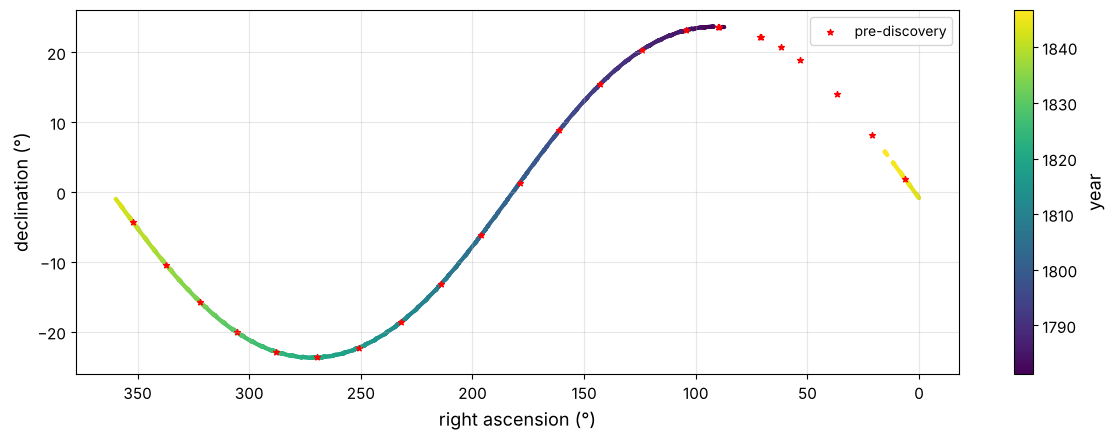

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
recent = obs[obs["year"] > 1781]
sc = ax.scatter(recent["ra"], recent["dec"], c=recent["year"], s=4, cmap="viridis")
old_pts = obs[obs["era"] == "pre-discovery"]
ax.scatter(old_pts["ra"], old_pts["dec"], c="red", s=18, marker="*", label="pre-discovery")
ax.invert_xaxis()
ax.set_xlabel("right ascension (°)"); ax.set_ylabel("declination (°)")
ax.grid(alpha=0.3); ax.legend()
plt.colorbar(sc, label="year")
save_fig("uranus_sky_path_plot")
plt.show()

In [8]:
# Semi-major axes known in 1845 (modern values, AU), with Titius-Bode index n
bode = pd.DataFrame({"a_AU": [0.387, 0.723, 1.000, 1.524, 2.77, 5.203, 9.537, 19.19],
                     "n": [-np.inf, 0, 1, 2, 3, 4, 5, 6]},
                    index=["Mercury", "Venus", "Earth", "Mars", "Ceres", "Jupiter",
                           "Saturn", "Uranus"])
bode["bode_rule"] = 0.4 + 0.3 * 2.0 ** bode["n"]
bode

,a_AU,n,bode_rule
Mercury,0.387,-inf,0.4
Venus,0.723,0.0,0.7
Earth,1.000,1.0,1.0
Mars,1.524,2.0,1.6
Ceres,2.770,3.0,2.8
Jupiter,5.203,4.0,5.2
Saturn,9.537,5.0,10.0
Uranus,19.190,6.0,19.6


In [9]:
from sklearn.linear_model import LinearRegression

fit_rows = bode[np.isfinite(bode["n"])]
X_bode = fit_rows[["n"]].values
y_bode = np.log2((fit_rows["a_AU"].values - 0.4) / 0.3)    # attribute combination
bode_reg = LinearRegression().fit(X_bode, y_bode)
n_next = 7
a_next = 0.4 + 0.3 * 2 ** bode_reg.predict([[n_next]])[0]
print(f"slope = {bode_reg.coef_[0]:.3f}, predicted distance of the next planet: {a_next:.1f} AU")

slope = 0.984, predicted distance of the next planet: 36.7 AU


## Prepare the Data for Machine Learning Algorithms

In [10]:
EPS_J2000 = np.radians(23.4392911)          # obliquity of the ecliptic at J2000

def radec_to_ecliptic(ra_deg, dec_deg):
    """Equatorial (ICRF) RA/Dec -> ecliptic longitude and latitude (radians)."""
    ra, dec = np.radians(ra_deg), np.radians(dec_deg)
    x = np.cos(dec) * np.cos(ra)
    y = np.cos(dec) * np.sin(ra)
    z = np.sin(dec)
    c, s = np.cos(EPS_J2000), np.sin(EPS_J2000)
    ye, ze = c * y + s * z, -s * y + c * z               # rotate about the x axis
    return np.arctan2(ye, x) % (2 * np.pi), np.arcsin(ze)

obs["lon"], obs["lat"] = radec_to_ecliptic(obs["ra"], obs["dec"])
train_set = obs.iloc[train_idx].copy()
test_set = obs.iloc[test_idx].copy()
obs[["year", "ra", "dec", "lon", "lat"]].head(3)

,year,ra,dec,lon,lat
0,1690.870637,62.04035,20.80414,1.117110,-0.002574
1,1692.896646,71.04406,22.26945,1.265462,-0.000453
2,1696.948665,89.85770,23.66057,1.568521,0.003863


In [11]:
from scipy.interpolate import CubicSpline

def spline(vec):
    return CubicSpline(vec["jd"].values, vec[["x", "y", "z"]].values)

earth_pos, jupiter_pos, saturn_pos = spline(earth), spline(jupiter), spline(saturn)
earth_pos(2451545.0)          # where the Earth was on 1 Jan 2000 (AU)

array([ 1.47009600e+08,  1.93792894e+07, -6.60154786e+05])

## Select and Train a Model

In [12]:
from scipy.integrate import solve_ivp

K2 = 0.01720209895 ** 2         # G * M_sun in AU³/day² (Gauss's constant squared)
M_JUPITER = 1 / 1047.348644     # masses in solar masses: known in 1845 from their moons
M_SATURN = 1 / 3497.9018
M_URANUS = 1 / 22902.98
LIGHT_DAYS_PER_AU = 0.0057755183
T_EPOCH = 2366000.5             # 1765: the middle of the data

def acceleration(t, r, perturbers):
    """Heliocentric acceleration of Uranus: the Sun + each perturber (direct and
    indirect terms: the perturber also pulls the Sun, our moving origin)."""
    acc = -K2 * (1 + M_URANUS) * r / np.linalg.norm(r) ** 3
    for position, mass in perturbers:
        p = position(t)
        d = p - r
        acc += K2 * mass * (d / np.linalg.norm(d) ** 3 - p / np.linalg.norm(p) ** 3)
    return acc

def integrate_orbit(state0, perturbers, t_min, t_max):
    """Integrate Uranus forward and backward from the epoch; returns a function of time."""
    rhs = lambda t, y: np.r_[y[3:], acceleration(t, y[:3], perturbers)]
    opts = dict(method="DOP853", rtol=1e-10, atol=1e-12, dense_output=True)
    fwd = solve_ivp(rhs, (T_EPOCH, t_max + 5), state0, **opts)
    bwd = solve_ivp(rhs, (T_EPOCH, t_min - 5), state0, **opts)
    def state(t):
        t = np.atleast_1d(t)
        out = np.empty((6, len(t)))
        after = t >= T_EPOCH
        if after.any():
            out[:, after] = fwd.sol(t[after])
        if (~after).any():
            out[:, ~after] = bwd.sol(t[~after])
        return out
    return state

def predict_sky(state0, perturbers, jd):
    """Geocentric ecliptic longitude/latitude of Uranus (with light-time correction)."""
    s = integrate_orbit(state0, perturbers, jd.min(), jd.max())(jd)
    g = s[:3] - earth_pos(jd).T                       # Earth -> Uranus
    g = g - s[3:] * np.linalg.norm(g, axis=0) * LIGHT_DAYS_PER_AU   # where it WAS
    return np.arctan2(g[1], g[0]) % (2 * np.pi), np.arctan2(g[2], np.hypot(g[0], g[1]))

def o_minus_c(state0, perturbers, data):
    """'Observed minus computed' in arcseconds: on-sky longitude, latitude."""
    lon, lat = predict_sky(state0, perturbers, data["jd"].values)
    dlon = np.angle(np.exp(1j * (data["lon"].values - lon))) * np.cos(data["lat"].values)
    return np.r_[dlon, data["lat"].values - lat] * 206265

In [13]:
# A rough starting guess: a circular orbit, in the ecliptic, at Kepler's distance for an
# 84-year period, at the longitude where Uranus was seen at the opposition nearest 1765.
a0 = (84.0 ** 2) ** (1 / 3)                                   # Kepler III, AU
near = obs.loc[(obs["jd"] - T_EPOCH).abs().idxmin()]
L0 = near["lon"]
v0 = np.sqrt(K2 / a0)
state_guess = np.array([a0 * np.cos(L0), a0 * np.sin(L0), 0.0,
                        -v0 * np.sin(L0), v0 * np.cos(L0), 0.0])
print(f"a ≈ {a0:.2f} AU, starting longitude {np.degrees(L0):.1f}°")

a ≈ 19.18 AU, starting longitude 22.7°


In [14]:
from sklearn.base import BaseEstimator, RegressorMixin
from scipy.optimize import least_squares

STATE_SCALE = np.r_[np.full(3, 1e-3), np.full(3, 1e-6)]    # AU and AU/day

class UranusOrbitRegressor(BaseEstimator, RegressorMixin):
    """Fits the position and velocity of Uranus in 1765 so that the simulated planet,
    pulled by the Sun and the given perturbers, matches the observed sky positions."""
    def __init__(self, perturbers="sun", init=None):
        self.perturbers = perturbers            # 'sun' or 'sun+jupiter+saturn'
        self.init = init
    def _bodies(self):
        if self.perturbers == "sun":
            return []
        return [(jupiter_pos, M_JUPITER), (saturn_pos, M_SATURN)]
    def fit(self, X, y=None):
        start = state_guess if self.init is None else self.init
        res = least_squares(o_minus_c, start, args=(self._bodies(), X),
                            x_scale=STATE_SCALE, diff_step=1e-7)
        self.state_ = res.x
        return self
    def residuals(self, X):
        return o_minus_c(self.state_, self._bodies(), X)
    def score(self, X, y=None):
        return -np.sqrt(np.mean(self.residuals(X) ** 2))      # minus RMS O-C (arcsec)

In [15]:
sun_only = UranusOrbitRegressor("sun").fit(train_set)
print(f"Sun only: RMS O-C = {-sun_only.score(train_set):.1f} arcsec")

Sun only: RMS O-C = 31.2 arcsec


In [16]:
bouvard = UranusOrbitRegressor("sun+jupiter+saturn", init=sun_only.state_).fit(train_set)
r = bouvard.residuals(train_set)
print(f"Sun + Jupiter + Saturn: RMS O-C = {-bouvard.score(train_set):.1f} arcsec, "
      f"max = {np.abs(r).max():.1f} arcsec")

Sun + Jupiter + Saturn: RMS O-C = 12.4 arcsec, max = 144.1 arcsec


In [17]:
def orbital_elements(state):
    """Semi-major axis, eccentricity, inclination from a heliocentric state vector."""
    r, v = state[:3], state[3:]
    mu = K2 * (1 + M_URANUS)
    a = 1 / (2 / np.linalg.norm(r) - v @ v / mu)
    h = np.cross(r, v)
    e = np.linalg.norm(np.cross(v, h) / mu - r / np.linalg.norm(r))
    inc = np.degrees(np.arccos(h[2] / np.linalg.norm(h)))
    return pd.Series({"a (AU)": a, "e": e, "i (deg)": inc,
                      "period (yr)": 2 * np.pi / np.sqrt(mu / a**3) / 365.25})

orbital_elements(bouvard.state_).round(4)

a (AU)         19.2184
e               0.0471
i (deg)         0.7792
period (yr)    84.2511
dtype: float64

In [18]:
from sklearn.model_selection import GroupKFold

def cross_val_rms(make_model, data, n_splits=5):
    scores = []
    for tr, va in GroupKFold(n_splits).split(data, groups=data["apparition"]):
        model = make_model().fit(data.iloc[tr])
        scores.append(-model.score(data.iloc[va]))
    return np.array(scores)

def display_scores(scores):
    print("Scores:", scores.round(2))
    print("Mean:", scores.mean().round(3), " Standard deviation:", scores.std().round(3))

for name, make in [("Sun only", lambda: UranusOrbitRegressor("sun", init=sun_only.state_)),
                   ("Sun + Jupiter + Saturn",
                    lambda: UranusOrbitRegressor("sun+jupiter+saturn", init=bouvard.state_))]:
    print("---", name, "---"); display_scores(cross_val_rms(make, train_set))

--- Sun only ---


Scores: [36.76 30.26 33.11 29.86 32.36]
Mean: 32.469  Standard deviation: 2.471
--- Sun + Jupiter + Saturn ---


Scores: [10.46  8.72 15.45 17.88 15.92]
Mean: 13.687  Standard deviation: 3.485


Saving figure uranus_o_minus_c_plot


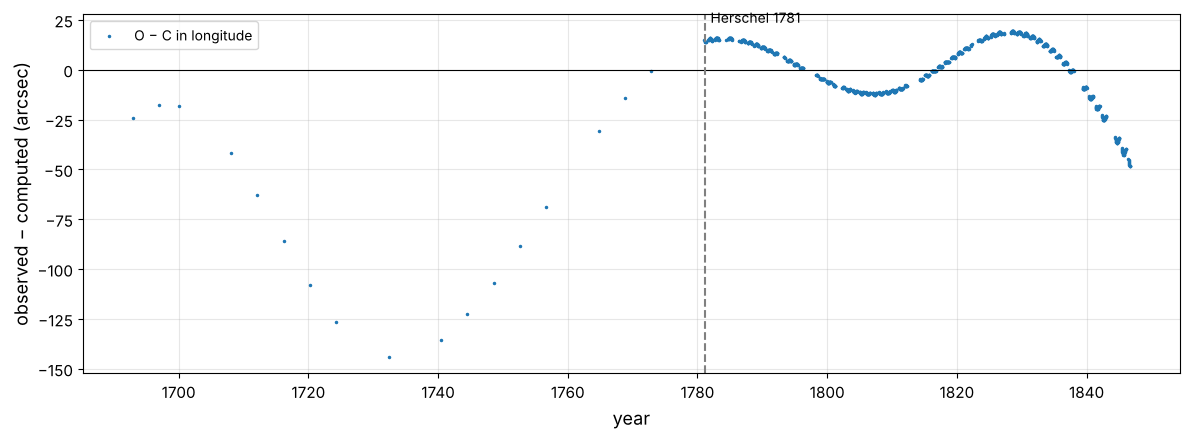

In [19]:
def plot_o_minus_c(data, resid, ax, label, **kw):
    n = len(data)
    ax.plot(data["year"], resid[:n], ".", ms=3, label=label, **kw)

fig, ax = plt.subplots(figsize=(12, 4.5))
plot_o_minus_c(train_set, bouvard.residuals(train_set), ax, "O − C in longitude")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(1781.2, color="gray", ls="--"); ax.text(1782, ax.get_ylim()[1] * 0.85, "Herschel 1781")
ax.set_xlabel("year"); ax.set_ylabel("observed − computed (arcsec)")
ax.grid(alpha=0.3); ax.legend()
save_fig("uranus_o_minus_c_plot")
plt.show()

## Fine-Tune Your Model

In [20]:
# Linearize around Bouvard's solution: how does O-C change if we nudge Uranus's state?
base_resid = bouvard.residuals(obs)
steps = np.r_[np.full(3, 1e-5), np.full(3, 1e-8)]
jacobian = np.column_stack([
    (o_minus_c(bouvard.state_ + np.eye(6)[k] * steps[k], bouvard._bodies(), obs) - base_resid) / steps[k]
    for k in range(6)])
jacobian.shape

(3174, 6)

In [21]:
from sklearn.base import TransformerMixin

M_PROBE = 1e-4              # a probe mass (solar masses): the response is ~linear in mass
_x_cache = {}

def planet_x_position(a, lon0):
    """Circular orbit in the ecliptic (Le Verrier's assumption), Kepler III for the speed."""
    n = np.sqrt(K2 / a ** 3)
    return lambda t: np.array([a * np.cos(lon0 + n * (t - T_EPOCH)),
                               a * np.sin(lon0 + n * (t - T_EPOCH)), 0.0])

def planet_x_signature(a, lon0_deg):
    """Change in O-C (per solar mass of planet X) for every observation."""
    key = (round(a, 3), round(lon0_deg, 3))
    if key not in _x_cache:
        bodies = bouvard._bodies() + [(planet_x_position(a, np.radians(lon0_deg)), M_PROBE)]
        _x_cache[key] = (o_minus_c(bouvard.state_, bodies, obs) - base_resid) / M_PROBE
    return _x_cache[key]

class PlanetXFeatures(BaseEstimator, TransformerMixin):
    """Rows = measured numbers (index into the stacked O-C vector).
    Features = 6 'nudge Uranus' columns + 1 'planet X at (a, lon0)' column."""
    def __init__(self, a=36.0, lon0=0.0):
        self.a = a
        self.lon0 = lon0
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        rows = np.asarray(X).ravel().astype(int)
        return np.c_[jacobian[rows], planet_x_signature(self.a, self.lon0)[rows]]

In [22]:
# Each observation gives two numbers (longitude and latitude O-C).
n_obs = len(obs)
rows_of = lambda idx: np.r_[idx, idx + n_obs]
X_train_rows = rows_of(train_idx).reshape(-1, 1)
y_train = -base_resid[X_train_rows.ravel()]          # what the corrections must explain
groups_train = np.r_[obs["apparition"].values[train_idx]] .tolist() * 2
X_train_rows.shape, y_train.shape

((2592, 1), (2592,))

In [23]:
from sklearn.pipeline import Pipeline

planet_x_model = Pipeline([
    ("planet_x", PlanetXFeatures()),
    ("lin_reg", LinearRegression(fit_intercept=False)),
])

def rms_score(estimator, X, y):
    return -np.sqrt(np.mean((estimator.predict(X) - y) ** 2))

In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {"planet_x__a": [20.0, 24.0, 26.0, 28.0, 30.0, 32.0, 34.0, 36.0, 38.8, 44.0],
              "planet_x__lon0": list(np.arange(0.0, 360.0, 7.5))}
grid_search = GridSearchCV(planet_x_model, param_grid, cv=GroupKFold(5),
                           scoring=rms_score, n_jobs=1)
grid_search.fit(X_train_rows, y_train, groups=groups_train)
grid_search.best_params_

{'planet_x__a': 30.0, 'planet_x__lon0': np.float64(150.0)}

Saving figure planet_x_grid_search_plot


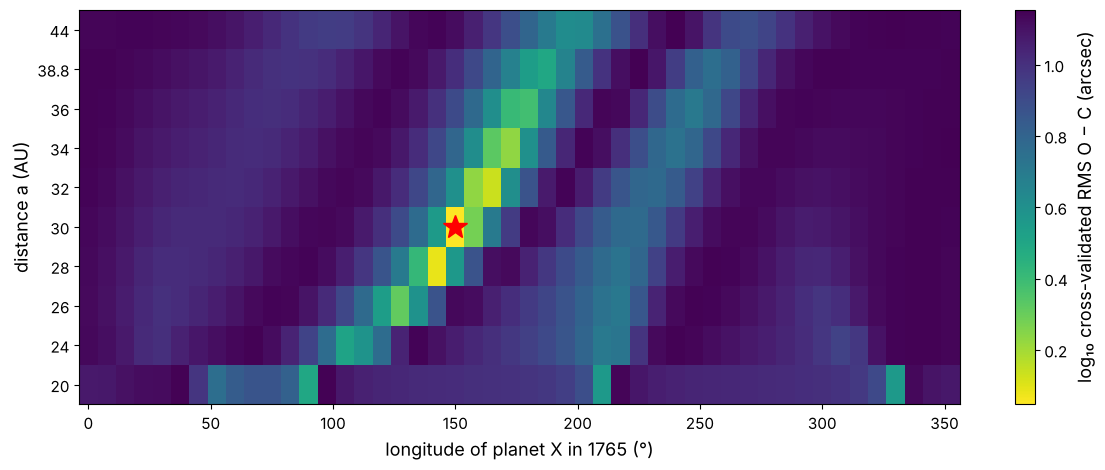

In [25]:
res = pd.DataFrame(grid_search.cv_results_["params"])
res["rms"] = -grid_search.cv_results_["mean_test_score"]
table = res.pivot(index="planet_x__a", columns="planet_x__lon0", values="rms")
fig, ax = plt.subplots(figsize=(12, 4.8))
im = ax.imshow(np.log10(table.values), aspect="auto", origin="lower", cmap="viridis_r",
               extent=[-3.75, 356.25, -0.5, len(table) - 0.5])
ax.set_yticks(range(len(table)), [f"{a:g}" for a in table.index])
ax.set_xlabel("longitude of planet X in 1765 (°)"); ax.set_ylabel("distance a (AU)")
best = grid_search.best_params_
ax.plot(best["planet_x__lon0"], list(table.index).index(best["planet_x__a"]), "r*", ms=18)
plt.colorbar(im, label="log₁₀ cross-validated RMS O − C (arcsec)")
save_fig("planet_x_grid_search_plot")
plt.show()

In [26]:
best_lon = table.idxmin(axis=1)
summary = pd.DataFrame({"best lon0": best_lon, "CV RMS (arcsec)": table.min(axis=1)})
mass = []
for a, lon in best_lon.items():
    model = Pipeline([("planet_x", PlanetXFeatures(a, lon)),
                      ("lin_reg", LinearRegression(fit_intercept=False))]).fit(X_train_rows, y_train)
    mass.append(model.named_steps["lin_reg"].coef_[-1])
summary["mass (M_sun)"] = mass
summary.round(6)

,best lon0,CV RMS (arcsec),mass (M_sun)
planet_x__a,,,
20.0,90.0,3.133968,0.000076
24.0,105.0,3.236599,0.000007
26.0,127.5,2.065724,0.000017
28.0,142.5,1.211502,0.000031
30.0,150.0,1.114820,0.000047
32.0,165.0,1.365740,0.000075
34.0,172.5,1.703193,0.000104
36.0,180.0,2.402134,0.000139
38.8,187.5,3.129870,0.000195


In [27]:
# Final model: full non-linear fit (no linearization) of Uranus's state and planet X's
# mass and longitude, at the best distance found by the grid search.
A_X = best["planet_x__a"]

def full_residuals(q, data):
    state, m, lon0 = q[:6], q[6] * 1e-5, np.radians(q[7])
    bodies = bouvard._bodies() + [(planet_x_position(A_X, lon0), m)]
    return o_minus_c(state, bodies, data)

lin = Pipeline([("planet_x", PlanetXFeatures(A_X, best["planet_x__lon0"])),
                ("lin_reg", LinearRegression(fit_intercept=False))]).fit(X_train_rows, y_train)
q0 = np.r_[bouvard.state_ + lin.named_steps["lin_reg"].coef_[:6],
           lin.named_steps["lin_reg"].coef_[6] * 1e5, best["planet_x__lon0"]]
final = least_squares(full_residuals, q0, args=(train_set,),
                      x_scale=np.r_[STATE_SCALE, 1.0, 1.0], diff_step=np.r_[np.full(6, 1e-7), 1e-3, 1e-4])
x_mass, x_lon0 = final.x[6] * 1e-5, final.x[7] % 360
print(f"planet X: a = {A_X} AU, mass = {x_mass:.3g} M_sun ({x_mass * 332946:.1f} Earth masses), "
      f"longitude in 1765 = {x_lon0:.1f}°")
print(f"training RMS O-C: {np.sqrt(np.mean(final.fun ** 2)):.2f} arcsec "
      f"(was {-bouvard.score(train_set):.1f} without planet X)")

planet X: a = 30.0 AU, mass = 4.84e-05 M_sun (16.1 Earth masses), longitude in 1765 = 152.7°
training RMS O-C: 0.54 arcsec (was 12.4 without planet X)


Saving figure o_minus_c_before_after_plot


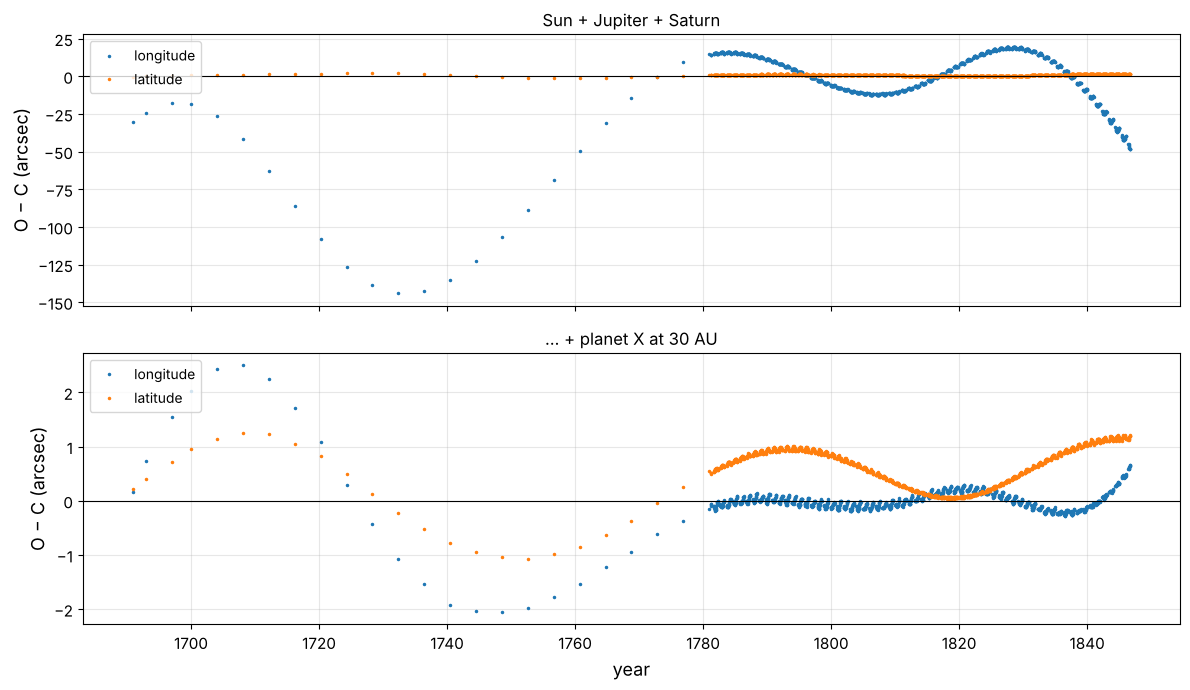

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
r_before = bouvard.residuals(obs)
r_after = full_residuals(final.x, obs)
for ax, r, title in [(axes[0], r_before, "Sun + Jupiter + Saturn"),
                     (axes[1], r_after, f"… + planet X at {A_X:g} AU")]:
    ax.plot(obs["year"], r[:n_obs], ".", ms=3, label="longitude")
    ax.plot(obs["year"], r[n_obs:], ".", ms=3, label="latitude")
    ax.axhline(0, color="k", lw=0.8); ax.set_title(title)
    ax.set_ylabel("O − C (arcsec)"); ax.grid(alpha=0.3); ax.legend(loc="upper left")
axes[1].set_xlabel("year")
save_fig("o_minus_c_before_after_plot")
plt.show()

## Evaluate Your System on the Test Set

In [29]:
rms_before = np.sqrt(np.mean(bouvard.residuals(test_set) ** 2))
rms_after = np.sqrt(np.mean(full_residuals(final.x, test_set) ** 2))
print(f"test RMS O-C without planet X: {rms_before:.2f} arcsec")
print(f"test RMS O-C with planet X:    {rms_after:.2f} arcsec")

test RMS O-C without planet X: 12.81 arcsec
test RMS O-C with planet X:    0.56 arcsec


## Launch: Point the Telescope

In [30]:
JD_GALLE = 2395197.5            # 23 September 1846, the night of the discovery

def geocentric_radec(helio_xyz, jd):
    g = helio_xyz - earth_pos(jd)
    c, s = np.cos(EPS_J2000), np.sin(EPS_J2000)
    x, y, z = g[0], c * g[1] - s * g[2], s * g[1] + c * g[2]       # ecliptic -> equatorial
    return np.degrees(np.arctan2(y, x)) % 360, np.degrees(np.arcsin(z / np.linalg.norm(g)))

x_pos_1846 = planet_x_position(A_X, np.radians(x_lon0))(JD_GALLE)
pred_ra, pred_dec = geocentric_radec(x_pos_1846, JD_GALLE)
print(f"predicted position of planet X on 1846-09-23: RA = {pred_ra:.2f}°, Dec = {pred_dec:.2f}°")
print(f"heliocentric longitude: {np.degrees(np.arctan2(x_pos_1846[1], x_pos_1846[0])) % 360:.2f}°")

predicted position of planet X on 1846-09-23: RA = 328.98°, Dec = -12.60°
heliocentric longitude: 327.86°


In [31]:
neptune_sky = fetch_observations("8", "neptune_1846", "1846-09-23", "1846-09-24", "1d")
nep_ra, nep_dec = neptune_sky.loc[0, ["ra", "dec"]]
cos_sep = (np.sin(np.radians(pred_dec)) * np.sin(np.radians(nep_dec)) +
           np.cos(np.radians(pred_dec)) * np.cos(np.radians(nep_dec)) *
           np.cos(np.radians(pred_ra - nep_ra)))
separation = np.degrees(np.arccos(cos_sep))
print(f"Neptune (NASA/JPL) on 1846-09-23: RA = {nep_ra:.2f}°, Dec = {nep_dec:.2f}°")
print(f"distance between our prediction and Neptune: {separation:.2f}°")

Neptune (NASA/JPL) on 1846-09-23: RA = 330.40°, Dec = -12.67°
distance between our prediction and Neptune: 1.39°


Saving figure galle_search_plot


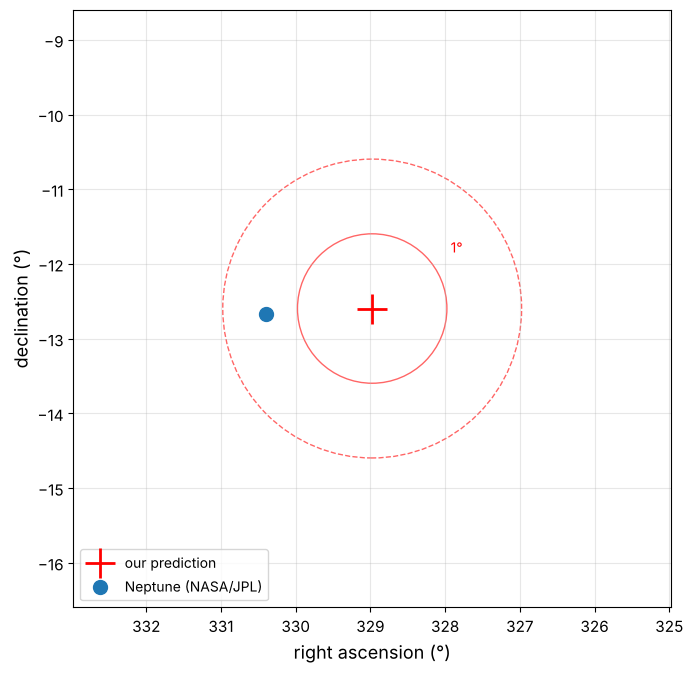

In [32]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(pred_ra, pred_dec, "r+", ms=22, mew=2, label="our prediction")
ax.plot(nep_ra, nep_dec, "o", color="tab:blue", ms=10, label="Neptune (NASA/JPL)")
for radius, ls in [(1, "-"), (2, "--")]:
    circle = plt.Circle((pred_ra, pred_dec), radius, fill=False, ls=ls, color="r", alpha=0.6)
    ax.add_patch(circle)
ax.text(pred_ra - 1.05, pred_dec + 0.75, "1°", color="r")
ax.set_xlim(pred_ra + 4, pred_ra - 4); ax.set_ylim(pred_dec - 4, pred_dec + 4)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="lower left")
ax.set_xlabel("right ascension (°)"); ax.set_ylabel("declination (°)")
save_fig("galle_search_plot")
plt.show()

In [33]:
neptune_vec = fetch_vectors("8", "neptune")
nep_xyz = spline(neptune_vec)(JD_GALLE)
true_lon = np.degrees(np.arctan2(nep_xyz[1], nep_xyz[0])) % 360
pd.DataFrame({"our planet X": [A_X, x_mass, np.degrees(np.arctan2(x_pos_1846[1], x_pos_1846[0])) % 360],
              "Neptune (NASA)": [np.linalg.norm(nep_xyz), 1 / 19412.26, true_lon]},
             index=["distance in 1846 (AU)", "mass (M_sun)", "heliocentric longitude 1846 (°)"]).round(6)

,our planet X,Neptune (NASA)
distance in 1846 (AU),30.000000,30.023592
mass (M_sun),0.000048,0.000052
heliocentric longitude 1846 (°),327.858903,326.904688


In [34]:
import json
os.makedirs("animations", exist_ok=True)
years = obs["year"].values
anim = {"years": years.round(3).tolist(),
        "oc_before": r_before[:n_obs].round(2).tolist(),
        "oc_after": r_after[:n_obs].round(2).tolist(),
        "a_x": A_X, "lon0_x": float(x_lon0), "mass_x": float(x_mass),
        "t_epoch": T_EPOCH,
        "grid": {"a": [float(a) for a in table.index], "lon0": [float(l) for l in table.columns],
                 "rms": np.log10(table.values).round(3).tolist()},
        "pred_radec": [float(pred_ra), float(pred_dec)], "neptune_radec": [float(nep_ra), float(nep_dec)]}
t_grid = np.arange(2337000.5, 2395300.5, 60.0)
st = integrate_orbit(final.x[:6], bouvard._bodies() + [(planet_x_position(A_X, np.radians(x_lon0)), x_mass)],
                     t_grid.min(), t_grid.max())(t_grid)
anim["track"] = {"jd": t_grid.tolist(),
                 "uranus": st[:2].T.round(4).tolist(),
                 "jupiter": jupiter_pos(t_grid)[:, :2].round(4).tolist(),
                 "saturn": saturn_pos(t_grid)[:, :2].round(4).tolist(),
                 "neptune": spline(neptune_vec)(t_grid)[:, :2].round(4).tolist()}
with open(os.path.join("animations", "fitted_parameters.json"), "w") as f:
    json.dump(anim, f)
print(len(t_grid), "animation frames")

972 animation frames
